In [1]:
# ================================================================
# CRDL C3-20 — FHWA SEVERITY REFERENCE & BACKEND CONTRACT
# ONE COLAB CELL | NO RETRAINING | NO UPLOADS
# ================================================================

from pathlib import Path
from datetime import datetime, timezone

import csv
import hashlib
import importlib.util
import json
import shutil
import uuid
import zipfile

import numpy as np
import torch


# ================================================================
# 1. RESTORE THE EXISTING C3-19 RELEASE
# ================================================================

ROOT = Path('/content/drive/MyDrive')

if not ROOT.is_dir():

    from google.colab import drive
    drive.mount('/content/drive')

PROJECT = (
    ROOT
    / 'crdl_experiments'
    / 'component3_fresh_v1'
)

SOURCE = (
    PROJECT
    / '08_integration'
    / 'C3-19_release_candidate_20261021T091823Z_651136'
)

REQUIRED = [
    'selected_model.pt',
    'model_and_inference.py',
    'component3_service.py',
    'geometry_measurements.py',
    'component3_measurement_service.py',
    'component3_handoff_service.py',
    'component3_bridge.py',
    'bundle_config.json',
    'api_contract.json'
]

assert all(
    (SOURCE / n).is_file()
    for n in REQUIRED
), 'C3-19 release files missing'


# ================================================================
# 2. REPRODUCIBILITY HELPERS
# ================================================================

def sha(p):

    h = hashlib.sha256()

    with Path(p).open('rb') as f:

        for block in iter(
            lambda: f.read(1024 * 1024),
            b''
        ):
            h.update(block)

    return h.hexdigest()


def dump(path, obj):

    Path(path).write_text(
        json.dumps(
            obj,
            indent=2,
            allow_nan=False
        ),
        encoding='utf-8'
    )


# ================================================================
# 3. CREATE VERSIONED SEVERITY RELEASE
# ================================================================

old_hashes = {
    n: sha(SOURCE / n)
    for n in REQUIRED
}

RUN = (
    PROJECT
    / '08_integration'
    / (
        'C3-20_severity_policy_'
        + datetime.now(
            timezone.utc
        ).strftime('%Y%m%dT%H%M%SZ_')
        + uuid.uuid4().hex[:6]
    )
)

RUN.mkdir(
    parents=True,
    exist_ok=False
)

for name in REQUIRED:

    shutil.copy2(
        SOURCE / name,
        RUN / name
    )

    assert (
        sha(RUN / name)
        == old_hashes[name]
    )

print('=' * 70)
print('CRDL C3-20 — SEVERITY POLICY INITIALIZATION')
print('=' * 70)
print('Source model integrity: PASS')
print('Output:', RUN)


# ================================================================
# 4. IMPLEMENT PUBLISHED FIELD SEVERITY POLICY
# ================================================================

# IMPORTANT:
# This module classifies independently measured
# pothole depth, not predictions in RAW sensor units.
#
# FHWA:
# LOW      < 25 mm
# MODERATE 25–50 mm
# HIGH     > 50 mm
#
# Applicable to qualifying asphalt-concrete potholes.

POLICY_SOURCE = r'''
import math

POLICY_VERSION = "C3-20.1.0"

STANDARD_ID = (
    "FHWA-HRT-13-092_ACP_8_POTHOLES_2014"
)

STANDARD_URL = (
    "https://www.fhwa.dot.gov/publications/"
    "research/infrastructure/pavements/ltpp/"
    "13092/001.cfm"
)


def severity_band(depth_mm):

    if (
        isinstance(depth_mm, bool)
        or not isinstance(
            depth_mm,
            (int, float)
        )
    ):
        raise ValueError(
            "depth_mm must be a numeric "
            "maximum physical depth"
        )

    d = float(depth_mm)

    if not math.isfinite(d) or d <= 0:

        raise ValueError(
            "depth_mm must be finite and > 0"
        )

    if d < 25.0:
        return "LOW"

    if d <= 50.0:
        return "MODERATE"

    return "HIGH"


def _number(
    value,
    field,
    *,
    zero_allowed=False
):

    if value is None or value == "":
        return None

    if isinstance(value, bool):

        raise ValueError(
            field + " must be numeric"
        )

    try:
        z = float(value)

    except (ValueError, TypeError):

        raise ValueError(
            field + " must be numeric"
        ) from None

    if (
        not math.isfinite(z)
        or z < 0
        or (z == 0 and not zero_allowed)
    ):

        raise ValueError(
            field + " has invalid value"
        )

    return z


def _true(v):

    # Blank fields are never automatically
    # treated as verified evidence.

    return (
        v is True
        or (
            isinstance(v, str)
            and v.strip().lower() == "true"
        )
    )


def evaluate_field_reference(field=None):

    result = {

        "source":
            "MANUAL_FIELD_REFERENCE_ONLY",

        "standard_id":
            STANDARD_ID,

        "standard_url":
            STANDARD_URL,

        "status":
            "NOT_PROVIDED",

        "reference_severity_nominal":
            None,

        "reference_severity_uncertainty_robust":
            None,

        "model_predicted_severity":
            None,

        "max_depth_mm":
            None,

        "uncertainty_mm":
            None,

        "nine_point_depths_available":
            False,

        "nine_point_mean_mm":
            None,

        "nine_point_max_mm":
            None,

        "road_plan_definition_verified":
            False,

        "measurement_quality_warnings":
            [],

        "not_a_model_prediction":
            True
    }

    if field is None:
        return result

    if not isinstance(field, dict):

        raise ValueError(
            "Field reference must be a dictionary"
        )

    # ------------------------------------------------
    # VERIFY DECLARED FIELD-MEASUREMENT SOURCE
    # ------------------------------------------------

    if field.get("source") != (
        "MANUAL_FIELD_MEASUREMENT"
    ):

        result["status"] = (
            "UNVERIFIED_FIELD_SOURCE"
        )

        return result

    # ------------------------------------------------
    # FHWA ASPHALT-PAVEMENT APPLICABILITY
    # ------------------------------------------------

    if field.get("road_surface_type") != (
        "ASPHALT_CONCRETE"
    ):

        result["status"] = (
            "FHWA_ACP_STANDARD_NOT_APPLICABLE"
            "_OR_UNCONFIRMED"
        )

        return result

    # ------------------------------------------------
    # FHWA MINIMUM POTHOLE PLAN DIMENSION
    # ------------------------------------------------

    if not _true(
        field.get(
            "fhwa_150mm_inscribed_circle_confirmed"
        )
    ):

        result["status"] = (
            "FHWA_POTHOLE_SIZE_DEFINITION"
            "_NOT_CONFIRMED"
        )

        return result

    result[
        "road_plan_definition_verified"
    ] = True

    # ------------------------------------------------
    # VERIFY ROAD-SURFACE DEPTH REFERENCE
    # ------------------------------------------------

    if not _true(
        field.get(
            "healthy_road_reference_verified"
        )
    ):

        result["status"] = (
            "FIELD_ROAD_REFERENCE_NOT_CONFIRMED"
        )

        return result

    # ------------------------------------------------
    # REQUIRE DOCUMENTED MEASUREMENT METHOD
    # ------------------------------------------------

    if field.get("measurement_method") not in (
        "STRAIGHTEDGE_RULER",
        "ROAD_REFERENCE_DEPTH_GAUGE"
    ):

        result["status"] = (
            "FIELD_MEASUREMENT_METHOD"
            "_NOT_DOCUMENTED"
        )

        return result

    # ------------------------------------------------
    # PHYSICALLY MEASURED DEEPEST POINT
    # ------------------------------------------------

    depth = _number(
        field.get("deepest_point_mm"),
        "deepest_point_mm"
    )

    if depth is None:

        result["status"] = (
            "MISSING_DEEPEST_POINT_MEASUREMENT"
        )

        return result

    result["max_depth_mm"] = depth

    # ------------------------------------------------
    # OPTIONAL NINE-POINT DEPTH EVIDENCE
    # ------------------------------------------------

    points = field.get(
        "nine_point_depths_mm"
    )

    if points not in (None, ""):

        if (
            not isinstance(
                points,
                (list, tuple)
            )
            or len(points) != 9
        ):

            raise ValueError(
                "nine_point_depths_mm must "
                "contain exactly 9 readings"
            )

        values = [

            _number(
                x,
                "nine_point_depths_mm",
                zero_allowed=True
            )

            for x in points
        ]

        if any(x is None for x in values):

            raise ValueError(
                "Nine-point readings cannot "
                "contain blanks"
            )

        result[
            "nine_point_depths_available"
        ] = True

        result["nine_point_mean_mm"] = (
            sum(values) / 9
        )

        result["nine_point_max_mm"] = max(
            values
        )

        if max(values) > depth + 1e-9:

            result["status"] = (
                "CONTRADICTORY_DEPTH_MEASUREMENTS"
            )

            result[
                "measurement_quality_warnings"
            ].append(
                "A sampled point exceeds the "
                "recorded deepest point"
            )

            return result

    # ------------------------------------------------
    # NOMINAL FHWA REFERENCE SEVERITY
    # ------------------------------------------------

    result[
        "reference_severity_nominal"
    ] = severity_band(depth)

    # ------------------------------------------------
    # OPTIONAL MEASUREMENT UNCERTAINTY
    # ------------------------------------------------

    uncertainty = _number(

        field.get(
            "depth_uncertainty_mm"
        ),

        "depth_uncertainty_mm",

        zero_allowed=True
    )

    result["uncertainty_mm"] = uncertainty

    if uncertainty is None:

        result["status"] = (
            "REFERENCE_NOMINAL_"
            "UNCERTAINTY_UNREPORTED"
        )

        result[
            "measurement_quality_warnings"
        ].append(
            "Measurement uncertainty missing; "
            "nominal class is not "
            "uncertainty-robust"
        )

        return result

    lower = max(
        0.0,
        depth - uncertainty
    )

    upper = depth + uncertainty

    # ------------------------------------------------
    # CHECK WHETHER UNCERTAINTY CROSSES A BOUNDARY
    # ------------------------------------------------

    crosses_25 = (
        lower < 25.0 <= upper
    )

    crosses_50 = (
        lower <= 50.0 < upper
    )

    if crosses_25 or crosses_50:

        result["status"] = (
            "REFERENCE_THRESHOLD_AMBIGUOUS"
        )

        return result

    # ------------------------------------------------
    # STABLE LABEL UNDER REPORTED UNCERTAINTY
    # ------------------------------------------------

    result["status"] = (
        "REFERENCE_LABEL_STABLE_WITH_"
        "REPORTED_UNCERTAINTY"
    )

    result[
        "reference_severity_uncertainty_robust"
    ] = severity_band(depth)

    return result
'''

POLICY_FILE = RUN / 'severity_policy.py'

POLICY_FILE.write_text(
    POLICY_SOURCE,
    encoding='utf-8'
)


# ================================================================
# 5. CREATE EXTENDED BACKEND BRIDGE
# ================================================================

# The existing C3-19 API remains unchanged.
# Field severity is a separate optional output.
#
# This prevents manual ground-truth labels
# from being mistaken for ML predictions.

BRIDGE_SOURCE = r'''
from pathlib import Path
import importlib.util


class Component3SeverityBridge:

    def __init__(
        self,
        root,
        device="cpu"
    ):

        root = Path(root)

        spec = importlib.util.spec_from_file_location(
            "c320_underlying_bridge",
            root / "component3_bridge.py"
        )

        module = importlib.util.module_from_spec(
            spec
        )

        spec.loader.exec_module(module)

        policy_spec = (
            importlib.util.spec_from_file_location(
                "c320_field_policy",
                root / "severity_policy.py"
            )
        )

        policy = importlib.util.module_from_spec(
            policy_spec
        )

        policy_spec.loader.exec_module(
            policy
        )

        self.bridge = module.Component3Bridge(
            root,
            device=device
        )

        self.policy = policy

    def predict(
        self,
        rgb_uint8,
        detections,
        *,
        include_maps=False,
        field_measurements=None
    ):

        if (
            field_measurements is not None
            and not isinstance(
                field_measurements,
                dict
            )
        ):

            raise ValueError(
                "field_measurements must map "
                "defect_id to field record"
            )

        result = self.bridge.predict(
            rgb_uint8,
            detections,
            include_maps=include_maps
        )

        ids = {

            d["defect_id"]

            for d in result["defects"]
        }

        if (
            field_measurements
            and not set(
                field_measurements
            ).issubset(ids)
        ):

            raise ValueError(
                "Field measurement contains "
                "an unknown defect_id"
            )

        for defect in result["defects"]:

            field = (

                None

                if field_measurements is None

                else field_measurements.get(
                    defect["defect_id"]
                )
            )

            defect[
                "field_reference_severity"
            ] = (
                self.policy.evaluate_field_reference(
                    field
                )
            )

            # Model severity must still abstain.
            assert (
                defect["severity"]["physical_level"]
                is None
            )

            assert (
                defect["severity"]["visual_level"]
                is None
            )

        result[
            "field_reference_policy_version"
        ] = self.policy.POLICY_VERSION

        result[
            "field_reference_is_model_output"
        ] = False

        return result
'''

BRIDGE_FILE = (
    RUN / 'component3_severity_bridge.py'
)

BRIDGE_FILE.write_text(
    BRIDGE_SOURCE,
    encoding='utf-8'
)


# ================================================================
# 6. LOAD SAVED FIELD-SEVERITY MODULE
# ================================================================

spec = importlib.util.spec_from_file_location(
    'c320_severity_policy',
    POLICY_FILE
)

policy = importlib.util.module_from_spec(
    spec
)

spec.loader.exec_module(policy)


# ================================================================
# 7. DEFINE SYNTHETIC FIELD TEST RECORDS
# ================================================================

# These values are software-test fixtures.
# They are NOT the user's seven field potholes.

def field(
    depth,
    uncertainty=0,
    points=None
):

    return {

        'source':
            'MANUAL_FIELD_MEASUREMENT',

        'road_surface_type':
            'ASPHALT_CONCRETE',

        'fhwa_150mm_inscribed_circle_confirmed':
            True,

        'healthy_road_reference_verified':
            True,

        'measurement_method':
            'STRAIGHTEDGE_RULER',

        'deepest_point_mm':
            depth,

        'depth_uncertainty_mm':
            uncertainty,

        'nine_point_depths_mm':
            points
    }


checks = []


def test(name, condition):

    assert condition, name

    checks.append({

        'test': name,

        'status': 'PASS'
    })


# ================================================================
# 8. TEST FHWA LOW / MODERATE / HIGH BOUNDARIES
# ================================================================

for depth, expected in [

    (10, 'LOW'),
    (24.999, 'LOW'),
    (25, 'MODERATE'),
    (50, 'MODERATE'),
    (50.001, 'HIGH'),
    (70, 'HIGH')

]:

    result = policy.evaluate_field_reference(
        field(depth)
    )

    test(

        'exact threshold ' + str(depth),

        result[
            'reference_severity_uncertainty_robust'
        ] == expected
    )


# ================================================================
# 9. TEST DEPTH MEASUREMENT UNCERTAINTY
# ================================================================

test(

    'uncertainty crosses 25',

    policy.evaluate_field_reference(
        field(24.8, 0.5)
    )['status']
    == 'REFERENCE_THRESHOLD_AMBIGUOUS'
)

test(

    'uncertainty crosses 50',

    policy.evaluate_field_reference(
        field(50, 1)
    )[
        'reference_severity_uncertainty_robust'
    ] is None
)

test(

    'stable uncertainty',

    policy.evaluate_field_reference(
        field(30, 1)
    )[
        'reference_severity_uncertainty_robust'
    ] == 'MODERATE'
)

test(

    'missing uncertainty',

    policy.evaluate_field_reference(
        field(30, None)
    )['status']
    == 'REFERENCE_NOMINAL_UNCERTAINTY_UNREPORTED'
)


# ================================================================
# 10. TEST NINE-POINT MEASUREMENT CONSISTENCY
# ================================================================

test(

    'nine point agreement',

    policy.evaluate_field_reference(

        field(
            35,
            1,

            [
                10, 15, 20,
                25, 27, 30,
                22, 23, 28
            ]
        )

    )['nine_point_depths_available']
)

test(

    'nine point contradiction',

    policy.evaluate_field_reference(

        field(
            35,
            1,

            [
                10, 15, 20,
                25, 27, 36,
                22, 23, 28
            ]
        )

    )[
        'reference_severity_nominal'
    ] is None
)


# ================================================================
# 11. TEST MISSING EVIDENCE AND UNSUPPORTED SOURCES
# ================================================================

test(

    'no field data',

    policy.evaluate_field_reference()[
        'reference_severity_nominal'
    ] is None
)

test(

    'no model RAW to mm conversion',

    policy.evaluate_field_reference(

        {
            'source': 'MODEL_RAW',
            'deepest_point_mm': 40
        }

    )[
        'reference_severity_nominal'
    ] is None
)

test(

    'pavement applicability',

    policy.evaluate_field_reference(

        {
            **field(40),
            'road_surface_type': 'CONCRETE'
        }

    )[
        'reference_severity_nominal'
    ] is None
)

test(

    'minimum plan definition',

    policy.evaluate_field_reference(

        {
            **field(40),

            'fhwa_150mm_inscribed_circle_confirmed':
                False
        }

    )[
        'reference_severity_nominal'
    ] is None
)

test(

    'healthy-road reference',

    policy.evaluate_field_reference(

        {
            **field(40),

            'healthy_road_reference_verified':
                False
        }

    )[
        'reference_severity_nominal'
    ] is None
)


# ================================================================
# 12. INVALID MEASUREMENT REJECTION TESTS
# ================================================================

for bad in (
    -1,
    float('nan'),
    0
):

    try:

        policy.evaluate_field_reference(
            field(bad)
        )

        raise AssertionError(
            'Invalid depth was accepted'
        )

    except ValueError:

        checks.append({

            'test':
                'invalid depth ' + str(bad),

            'status':
                'PASS'
        })


print(
    'FHWA thresholds, provenance and '
    'uncertainty tests: PASS'
)


# ================================================================
# 13. CREATE SEVEN-POTHOLE FIELD DATA TEMPLATE
# ================================================================

# IDs are placeholders only.
# No measurements are fabricated.

columns = [

    'pothole_id',

    'source',

    'road_surface_type',

    'fhwa_150mm_inscribed_circle_confirmed',

    'healthy_road_reference_verified',

    'measurement_method',

    'deepest_point_mm',

    'depth_uncertainty_mm'

] + [

    f'point_{i:02d}_mm'

    for i in range(1, 10)

] + [

    'measured_length_mm',

    'measured_width_mm',

    'top_photo_path',

    'angle_photo_path',

    'measurement_date',

    'notes'
]

template = (
    RUN / 'seven_potholes_BLANK_FIELD_TEMPLATE.csv'
)

with template.open(
    'w',
    newline='',
    encoding='utf-8'
) as f:

    writer = csv.DictWriter(
        f,
        fieldnames=columns
    )

    writer.writeheader()

    for i in range(1, 8):

        writer.writerow({

            'pothole_id':
                f'SL_P{i:02d}'
        })


# ================================================================
# 14. LOAD THE REAL TRAINED COMPONENT 3 SERVICE
# ================================================================

spec = importlib.util.spec_from_file_location(
    'c320_severity_bridge',
    BRIDGE_FILE
)

mod = importlib.util.module_from_spec(
    spec
)

spec.loader.exec_module(mod)

service = mod.Component3SeverityBridge(

    RUN,

    device=(
        'cuda'
        if torch.cuda.is_available()
        else 'cpu'
    )
)

print('Real trained CRDL checkpoint: LOADED')


# ================================================================
# 15. GENERATE SYNTHETIC INTEGRATION INPUT
# ================================================================

y, x = np.indices(
    (192, 256)
)

rgb = np.stack(

    [
        x.astype('uint8'),

        y.astype('uint8'),

        np.full_like(
            x,
            100,
            dtype='uint8'
        )
    ],

    axis=2
)

mask = (

    ((x - 128) / 36) ** 2

    + ((y - 96) / 25) ** 2

    < 1
)

yy, xx = np.where(mask)

packet = {

    'defect_id':
        'SYNTHETIC_ONLY',

    'bbox_xyxy': [

        int(xx.min()),
        int(yy.min()),

        int(xx.max() + 1),
        int(yy.max() + 1)
    ],

    'mask_space':
        'frame',

    'mask':
        mask
}


# ================================================================
# 16. TEST MODEL INFERENCE WITHOUT FIELD MEASUREMENTS
# ================================================================

no_field = service.predict(

    rgb,

    [packet]

)['defects'][0]

test(

    'model severity remains null',

    no_field['severity'][
        'physical_level'
    ] is None
)

test(

    'field severity missing by default',

    no_field[
        'field_reference_severity'
    ]['status'] == 'NOT_PROVIDED'
)


# ================================================================
# 17. TEST SEPARATE FIELD-REFERENCE SEVERITY
# ================================================================

# Synthetic field measurement of 55 mm.
# This is a software test, NOT a real pothole.

with_field = service.predict(

    rgb,

    [packet],

    field_measurements={

        'SYNTHETIC_ONLY': field(

            55,

            1,

            [
                10, 15, 20,
                22, 30, 40,
                36, 32, 12
            ]
        )
    }

)['defects'][0]

test(

    'field reference separately classified',

    with_field[
        'field_reference_severity'
    ][
        'reference_severity_uncertainty_robust'
    ] == 'HIGH'
)

test(

    'model physical outputs still null',

    (
        with_field['severity'][
            'physical_level'
        ] is None

        and all(

            v is None

            for v in with_field[
                'physical_measurements'
            ].values()
        )
    )
)

test(

    'trained geometry inference still working',

    with_field[
        'geometry_raw'
    ]['d95_raw'] >= 0
)

print(
    'Trained-model and field-reference '
    'output separation: PASS'
)


# ================================================================
# 18. SAVE FROZEN SEVERITY POLICY REPORT
# ================================================================

policy_report = {

    'stage':
        'C3-20_SEVERITY_REFERENCE_POLICY',

    'standard_id':
        policy.STANDARD_ID,

    'standard_url':
        policy.STANDARD_URL,

    'rules': {

        'LOW':
            '0 < depth_mm < 25',

        'MODERATE':
            '25 <= depth_mm <= 50',

        'HIGH':
            'depth_mm > 50'
    },

    'condition':
        'Asphalt concrete, FHWA minimum size '
        'confirmed, healthy-road reference '
        'and field measurement documented',

    'classification_basis':
        'Measured maximum depth at separately '
        'identified deepest point; '
        'never the nine-point average',

    'depth_uncertainty':
        'Robust reference label only when '
        'declared uncertainty does not cross '
        'a severity threshold',

    'field_data_loaded':
        False,

    'field_measurement_template_rows':
        7,

    'model_physical_severity_enabled':
        False,

    'model_raw_to_mm_enabled':
        False,

    'validated_sri_lanka_specific_standard':
        False,

    'independent_field_model_accuracy_verified':
        False,

    'source_C319':
        str(SOURCE),

    'source_hashes':
        old_hashes
}

dump(
    RUN / 'severity_policy_report.json',
    policy_report
)


# ================================================================
# 19. SAVE SOFTWARE TEST EVIDENCE
# ================================================================

dump(

    RUN / 'test_results.json',

    {

        'total_passed':
            len(checks),

        'tests':
            checks,

        'all_tests_synthetic':
            True
    }
)


# ================================================================
# 20. DOCUMENT EXTENDED BACKEND API
# ================================================================

dump(

    RUN / 'api_severity_extension.json',

    {

        'entrypoint':

            'Component3SeverityBridge(bundle_dir, device)'
            '.predict(rgb_uint8, detections, '
            'include_maps=False, field_measurements=None)',

        'field_measurements':

            'Optional mapping: '
            'defect_id -> physical field record',

        'additional_output':

            'defects[].field_reference_severity',

        'unchanged_model_output':

            'defects[].severity.physical_level = null',

        'units':

            'Manual deepest_point_mm uses '
            'millimetres; no automatic RAW conversion',

        'required_field_evidence': [

            'source=MANUAL_FIELD_MEASUREMENT',

            'road_surface_type=ASPHALT_CONCRETE',

            'fhwa_150mm_inscribed_circle_confirmed=True',

            'healthy_road_reference_verified=True',

            'measurement_method=STRAIGHTEDGE_RULER '
            'or ROAD_REFERENCE_DEPTH_GAUGE',

            'deepest_point_mm must be positive'
        ],

        'optional': [

            'nine_point_depths_mm: 9 readings',

            'depth_uncertainty_mm: nonnegative'
        ]
    }
)


# ================================================================
# 21. SAVE REUSABLE DOCUMENTATION
# ================================================================

README = """
# CRDL C3-20 — Severity Policy

The FHWA ACP 8 pothole severity reference uses
independently measured maximum depression depth:

- LOW: below 25 mm
- MODERATE: 25 to 50 mm
- HIGH: above 50 mm

The applicable pavement and pothole-size criteria
must be checked.

This module does not classify CRDL RAW outputs
or independently certify real-world field accuracy.

The seven-row CSV is blank.
Record actual field measurements later.

For backend integration:

from component3_severity_bridge import Component3SeverityBridge

bridge = Component3SeverityBridge(
    bundle_root,
    device="cpu"
)

result = bridge.predict(
    rgb_uint8,
    detections,
    field_measurements=None
)
"""

(
    RUN / 'README_severity.md'
).write_text(
    README,
    encoding='utf-8'
)


# ================================================================
# 22. PACKAGE FOR VS CODE BACKEND
# ================================================================

zip_path = (
    RUN / 'C3-20_severity_ready_bundle.zip'
)

with zipfile.ZipFile(

    zip_path,

    'w',

    zipfile.ZIP_DEFLATED

) as z:

    for p in sorted(
        RUN.iterdir()
    ):

        if p.is_file() and p != zip_path:

            z.write(
                p,
                arcname=p.name
            )


with zipfile.ZipFile(
    zip_path
) as z:

    assert z.testzip() is None


# ================================================================
# 23. SAVE SHA-256 ARTIFACT MANIFEST
# ================================================================

receipts = [

    {

        'file':
            p.name,

        'sha256':
            sha(p),

        'bytes':
            p.stat().st_size
    }

    for p in sorted(
        RUN.iterdir()
    )

    if (
        p.is_file()

        and p.name != 'sha256_manifest.json'
    )
]

dump(
    RUN / 'sha256_manifest.json',
    receipts
)


# ================================================================
# 24. VERIFY ORIGINAL MODEL HAS NOT CHANGED
# ================================================================

assert all(

    sha(SOURCE / n) == old_hashes[n]

    for n in REQUIRED
)


# ================================================================
# 25. FINAL C3-20 RESULTS
# ================================================================

print('\n' + '=' * 70)

print(
    'C3-20 — FHWA FIELD SEVERITY POLICY COMPLETE'
)

print('=' * 70)

print(
    'Severity threshold and safety tests:',
    len(checks),
    'PASS'
)

print(
    'Real trained checkpoint through extended bridge: PASS'
)

print(
    'Seven-pothole blank CSV template: CREATED'
)

print(
    'Manual field-reference severity output: '
    'ENABLED WHEN SUPPORTED'
)

print(
    'Model-predicted metric severity: DISABLED'
)

print(
    'Existing C3-19 checkpoint and files: UNCHANGED'
)

print(
    'Physical model validation: NOT CLAIMED'
)

print(
    'VS Code severity bundle ZIP: CREATED'
)

print('\nSaved:')
print(RUN)

print('=' * 70)

Mounted at /content/drive
CRDL C3-20 — SEVERITY POLICY INITIALIZATION
Source model integrity: PASS
Output: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/08_integration/C3-20_severity_policy_20261021T103305Z_f99d24
FHWA thresholds, provenance and uncertainty tests: PASS
Real trained CRDL checkpoint: LOADED
Trained-model and field-reference output separation: PASS

C3-20 — FHWA FIELD SEVERITY POLICY COMPLETE
Severity threshold and safety tests: 25 PASS
Real trained checkpoint through extended bridge: PASS
Seven-pothole blank CSV template: CREATED
Manual field-reference severity output: ENABLED WHEN SUPPORTED
Model-predicted metric severity: DISABLED
Existing C3-19 checkpoint and files: UNCHANGED
Physical model validation: NOT CLAIMED
VS Code severity bundle ZIP: CREATED

Saved:
/content/drive/MyDrive/crdl_experiments/component3_fresh_v1/08_integration/C3-20_severity_policy_20261021T103305Z_f99d24


/tmp/ipykernel_971/1677801031.py:290: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  Image.fromarray(



CRDL C3-21 — ALIGNED INFERENCE
Sample: 20250227_135438
Original image: (480, 640)
Native CRDL map: (192, 256)
Upsampled visualization: (480, 640)
D95 RAW: 52.936805725097656
Reliability: REVIEW_ONLY_UNCALIBRATED


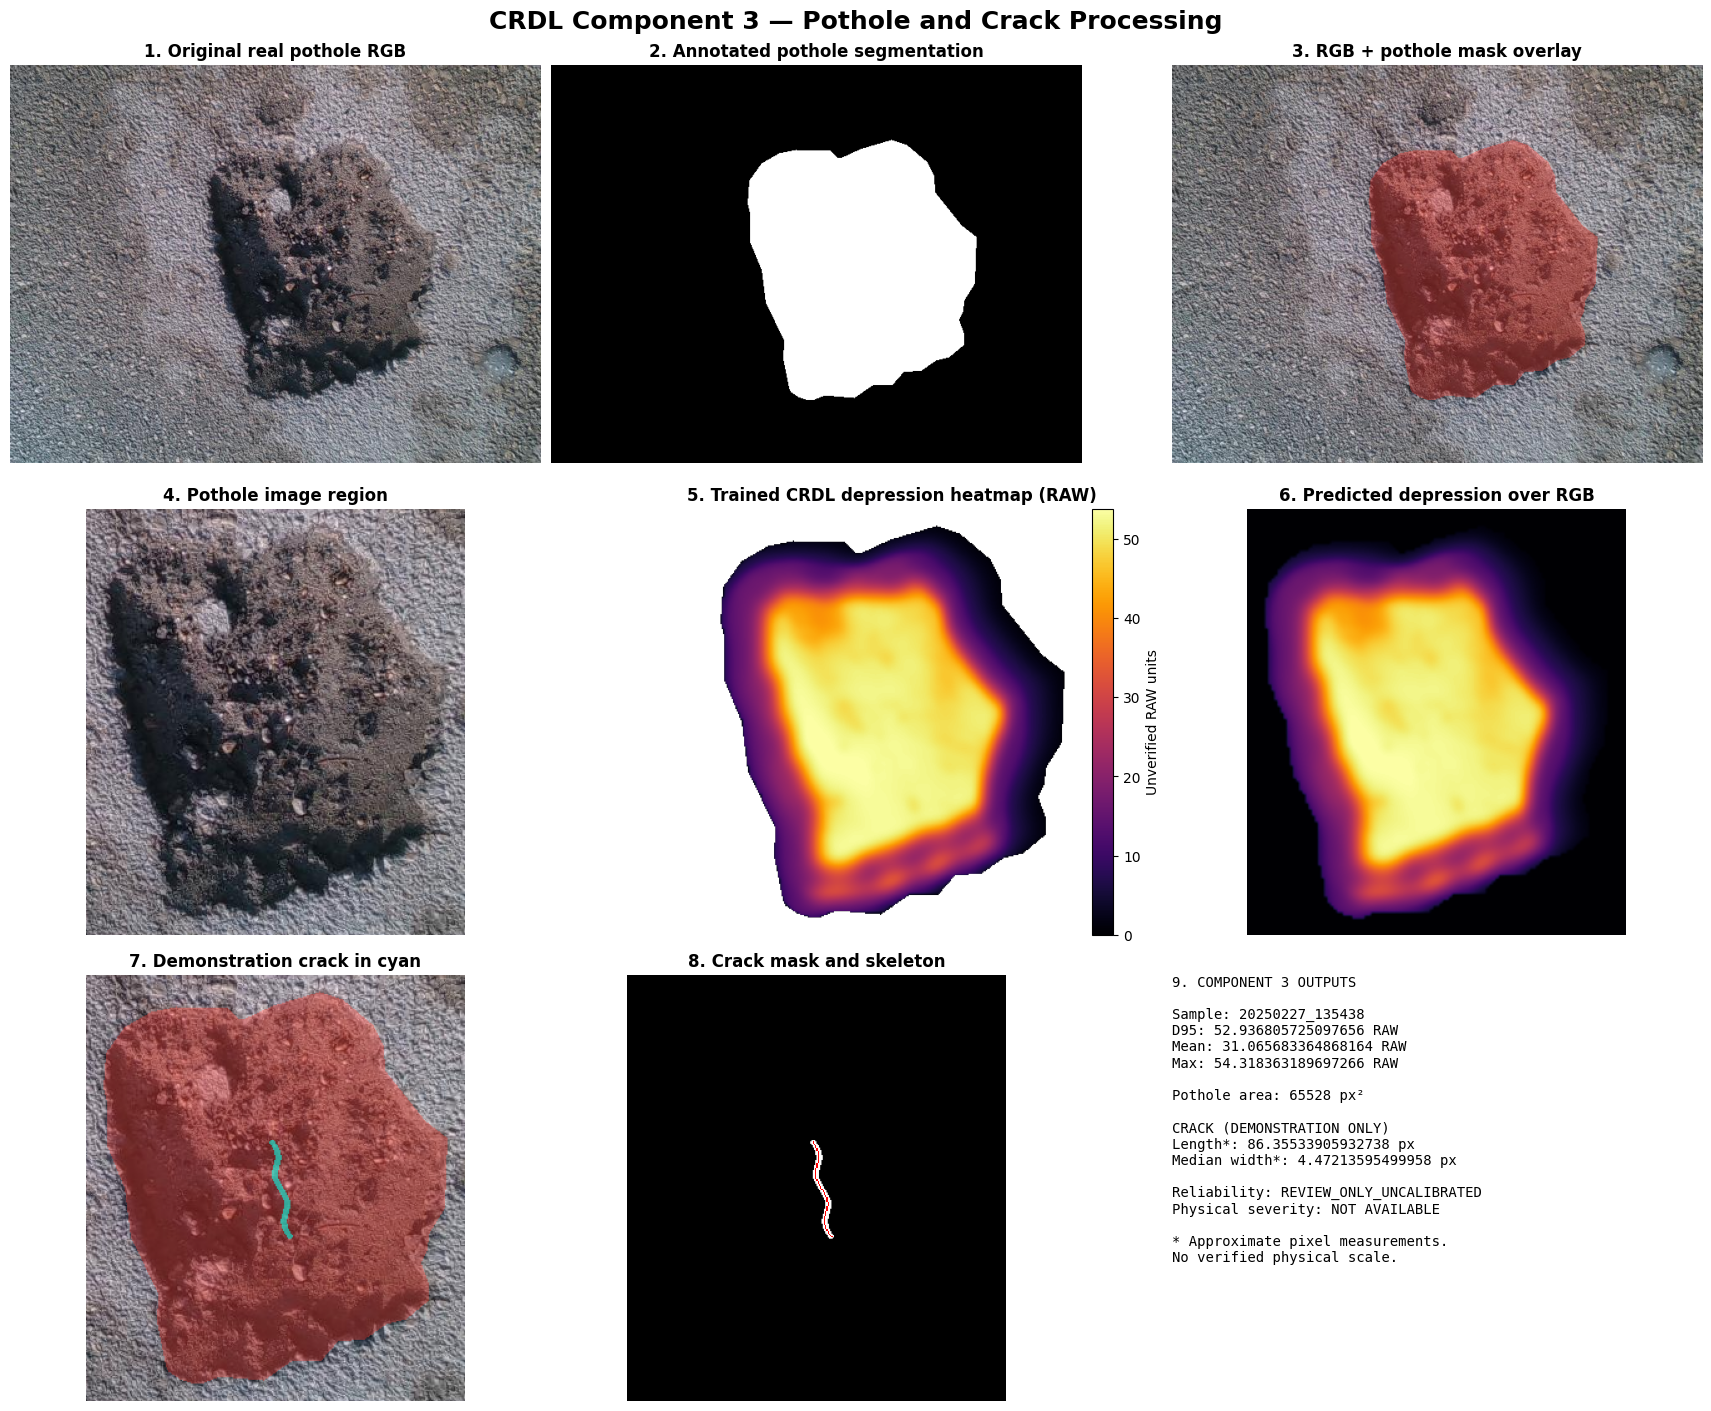


C3-21 FIXED — VISUAL PIPELINE COMPLETE
Native-to-RGB resolution alignment: PASS
Real trained CRDL inference: PASS
Crack procedure: DEMONSTRATION (synthetic mask, real measurement code)
Physical severity: NOT AVAILABLE

Visualization:
/content/drive/MyDrive/crdl_experiments/component3_fresh_v1/09_visualization/C3-21_visual_pipeline_FIXED_20261021T105644Z_5987be/20250227_135438_combined_pipeline_FIXED.png

Prediction arrays and scalar results:
/content/drive/MyDrive/crdl_experiments/component3_fresh_v1/09_visualization/C3-21_visual_pipeline_FIXED_20261021T105644Z_5987be


In [3]:
# ================================================================
# CRDL C3-21 FIXED — VISUAL POTHOLE + CRACK PIPELINE
# REAL TRAINED MODEL | ONE COLAB CELL | NO RETRAINING
# ================================================================

from pathlib import Path
from datetime import datetime, timezone
import csv, importlib.util, json, uuid
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from scipy.ndimage import distance_transform_edt, binary_dilation
from skimage.morphology import skeletonize

# ================================================================
# 1. EXACT SAVED PATHS
# ================================================================

ROOT = Path('/content/drive/MyDrive')

if not ROOT.is_dir():
    from google.colab import drive
    drive.mount('/content/drive')

PROJECT = ROOT / 'crdl_experiments' / 'component3_fresh_v1'

BUNDLE = (
    PROJECT / '08_integration'
    / 'C3-20_severity_policy_20261021T103305Z_f99d24'
)

ROLE_FILE = (
    PROJECT / '07_evaluation'
    / 'C3-09_physical_evidence_gate_v2_20261021T024723Z_ec15d662'
    / 'C3-10_section02_grouped_pilot_protocol_20261021T042524Z_735c9f'
    / 'PROVISIONAL_pilot_role_manifest.csv'
)

assert (BUNDLE / 'component3_severity_bridge.py').is_file()
assert ROLE_FILE.is_file()

# ================================================================
# 2. NEW VERSIONED OUTPUT FOLDER
# ================================================================

RUN = (
    PROJECT / '09_visualization'
    / (
        'C3-21_visual_pipeline_FIXED_'
        + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ_')
        + uuid.uuid4().hex[:6]
    )
)

RUN.mkdir(parents=True, exist_ok=False)

# ================================================================
# 3. SELECT THE SAME REAL POTHOLE IMAGE
# ================================================================

with ROLE_FILE.open(newline='', encoding='utf-8') as f:
    roles = list(csv.DictReader(f))

PREFERRED_SAMPLE_ID = '20250227_135438'

candidates = sorted(
    roles,
    key=lambda r: r['sample_id'] != PREFERRED_SAMPLE_ID
)

chosen = next(
    (
        r for r in candidates
        if Path(r['rgb_path']).is_file()
        and Path(r['label_path']).is_file()
    ),
    None
)

assert chosen is not None, 'No RGB and polygon pair found'

sid = chosen['sample_id']

with Image.open(chosen['rgb_path']) as im:
    rgb = np.asarray(im.convert('RGB'), dtype=np.uint8)

H, W = rgb.shape[:2]

# ================================================================
# 4. DECODE REAL POTHOLE SEGMENTATION
# ================================================================

def decode_yolo(path, h, w):

    canvas = Image.new('L', (w, h), 0)
    draw = ImageDraw.Draw(canvas)

    count = 0

    for line in Path(path).read_text(
        encoding='utf-8'
    ).splitlines():

        vals = np.fromstring(line, sep=' ', dtype=float)

        if vals.size == 0:
            continue

        if (
            len(vals) < 7
            or (len(vals) - 1) % 2 != 0
            or not np.isfinite(vals).all()
            or vals[0] != 0
            or not np.all(
                (vals[1:] >= 0) & (vals[1:] <= 1)
            )
        ):
            raise ValueError('Invalid class-0 YOLO polygon')

        pts = [
            (
                round(float(x) * (w - 1)),
                round(float(y) * (h - 1))
            )
            for x, y in vals[1:].reshape(-1, 2)
        ]

        draw.polygon(pts, fill=1)
        count += 1

    assert count > 0, 'No pothole polygon'

    return np.asarray(canvas, dtype=bool)


pothole = decode_yolo(
    chosen['label_path'],
    H, W
)

yy, xx = np.where(pothole)

bbox = [
    int(xx.min()),
    int(yy.min()),
    int(xx.max() + 1),
    int(yy.max() + 1)
]

# ================================================================
# 5. DEMONSTRATION CRACK MASK
# ================================================================

# NOTE:
# This is an artificial mask to demonstrate
# the real implemented crack measurement procedure.
# It is NOT a real detected crack.

distance = distance_transform_edt(pothole)

cy, cx = np.unravel_index(
    np.argmax(distance),
    distance.shape
)

radius = float(distance[cy, cx])

span = max(
    5,
    min(38, int(radius * 0.72))
)

crack_demo = np.zeros(
    (H, W),
    dtype=bool
)

for dy in range(-span, span + 1):

    y = cy + dy

    x = cx + round(
        0.19 * dy + 2.8 * np.sin(dy / 6.0)
    )

    if 0 <= y < H and 1 <= x < W - 1:
        crack_demo[y, x-1:x+2] = True

crack_demo &= pothole

crack_demo = (
    binary_dilation(crack_demo, iterations=1)
    & pothole
)

assert crack_demo.any()

crack_centerline = skeletonize(crack_demo)

# ================================================================
# 6. COLD-LOAD ACTUAL TRAINED CRDL SERVICE
# ================================================================

spec = importlib.util.spec_from_file_location(
    'c321_fixed_bridge',
    BUNDLE / 'component3_severity_bridge.py'
)

module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)

service = module.Component3SeverityBridge(
    BUNDLE,
    device='cpu'
)

# ================================================================
# 7. RUN ACTUAL COMPONENT 3 INFERENCE
# ================================================================

packet = {
    'defect_id': sid,
    'bbox_xyxy': bbox,
    'mask_space': 'frame',
    'mask': pothole,
    'crack_mask': crack_demo
}

response = service.predict(
    rgb,
    [packet],
    include_maps=True,
    field_measurements=None
)

defect = response['defects'][0]

raw_native = np.asarray(
    defect['raw_axial_depression_map'],
    dtype=np.float32
)

assert raw_native.shape == (192, 256), (
    f'Unexpected model output shape: {raw_native.shape}'
)

assert np.isfinite(raw_native).all()
assert (raw_native >= 0).all()

# ================================================================
# 8. CRITICAL FIX — ALIGN THE TWO RESOLUTIONS
# ================================================================

# ORIGINAL RGB: H x W (such as 480 x 640)
# NATIVE MODEL OUTPUT: 192 x 256
#
# A. Resize the pothole mask to model size
#    for native-resolution statistics.
#
# B. Resize a COPY of the depression map to
#    original RGB size for visualization.
#
# C. Never replace the actual native model
#    predictions used for numerical measurements.

mask_native = np.asarray(
    Image.fromarray(
        pothole.astype(np.uint8) * 255
    ).resize(
        (raw_native.shape[1], raw_native.shape[0]),
        Image.Resampling.NEAREST
    )
) > 0

assert mask_native.shape == raw_native.shape
assert mask_native.any()

raw_vmax = max(
    float(
        np.percentile(
            raw_native[mask_native],
            99
        )
    ),
    1e-6
)

# Visualization-only upsampling
raw_display = np.asarray(
    Image.fromarray(
        raw_native,
        mode='F'
    ).resize(
        (W, H),
        Image.Resampling.BILINEAR
    ),
    dtype=np.float32
)

raw_display = np.maximum(
    raw_display,
    0
)

assert raw_display.shape == pothole.shape

# ================================================================
# 9. PREPARE RGB-ALIGNED CROPS AND OVERLAYS
# ================================================================

x0, y0, x1, y1 = bbox

pad = 14

left = max(0, x0 - pad)
top = max(0, y0 - pad)
right = min(W, x1 + pad)
bottom = min(H, y1 + pad)

crop = np.s_[
    top:bottom,
    left:right
]

rgb_overlay = rgb.astype(
    np.float32
).copy()

rgb_overlay[pothole] = (
    0.62 * rgb_overlay[pothole]
    + 0.38 * np.array([255, 65, 55])
)

rgb_overlay = np.clip(
    rgb_overlay,
    0,
    255
).astype(np.uint8)

crack_overlay = rgb_overlay.astype(
    np.float32
).copy()

crack_overlay[crack_demo] = (
    0.4 * crack_overlay[crack_demo]
    + 0.6 * np.array([10, 255, 230])
)

crack_overlay = np.clip(
    crack_overlay,
    0,
    255
).astype(np.uint8)

# ================================================================
# 10. EXTRACT REAL MODEL AND MEASUREMENT OUTPUTS
# ================================================================

geom = defect.get('geometry_raw') or {}

pixels = defect.get(
    'pixel_measurements'
) or {}

crack_stats = pixels.get('crack') or {}

status = defect.get(
    'reliability_status',
    'UNKNOWN'
)

print('\n' + '=' * 65)
print('CRDL C3-21 — ALIGNED INFERENCE')
print('=' * 65)

print('Sample:', sid)
print('Original image:', (H, W))
print('Native CRDL map:', raw_native.shape)
print('Upsampled visualization:', raw_display.shape)
print('D95 RAW:', geom.get('d95_raw'))
print('Reliability:', status)

# ================================================================
# 11. BUILD THE COMBINED VISUAL WALKTHROUGH
# ================================================================

fig, axs = plt.subplots(
    3,
    3,
    figsize=(17, 14),
    constrained_layout=True
)

def show(ax, picture, title, **kwargs):

    ax.imshow(picture, **kwargs)
    ax.set_title(
        title,
        fontsize=12,
        fontweight='bold'
    )
    ax.axis('off')


# ORIGINAL AND SEGMENTATION
show(
    axs[0, 0],
    rgb,
    '1. Original real pothole RGB'
)

show(
    axs[0, 1],
    pothole,
    '2. Annotated pothole segmentation',
    cmap='gray'
)

show(
    axs[0, 2],
    rgb_overlay,
    '3. RGB + pothole mask overlay'
)

# GEOMETRY
show(
    axs[1, 0],
    rgb[crop],
    '4. Pothole image region'
)

heat = axs[1, 1].imshow(
    np.ma.masked_where(
        ~pothole[crop],
        raw_display[crop]
    ),
    cmap='inferno',
    vmin=0,
    vmax=raw_vmax
)

axs[1, 1].set_title(
    '5. Trained CRDL depression heatmap (RAW)',
    fontsize=12,
    fontweight='bold'
)

axs[1, 1].axis('off')

fig.colorbar(
    heat,
    ax=axs[1, 1],
    fraction=0.046,
    pad=0.02,
    label='Unverified RAW units'
)

show(
    axs[1, 2],
    rgb[crop],
    '6. Predicted depression over RGB'
)

axs[1, 2].imshow(
    raw_display[crop],
    cmap='inferno',
    vmin=0,
    vmax=raw_vmax,
    alpha=pothole[crop].astype(float) * 0.55
)

# CRACK DEMONSTRATION
show(
    axs[2, 0],
    crack_overlay[crop],
    '7. Demonstration crack in cyan'
)

show(
    axs[2, 1],
    crack_demo[crop],
    '8. Crack mask and skeleton',
    cmap='gray'
)

axs[2, 1].imshow(
    np.ma.masked_where(
        ~crack_centerline[crop],
        crack_centerline[crop]
    ),
    cmap='autumn',
    interpolation='nearest'
)

# SUMMARY
axs[2, 2].axis('off')

summary = '\n'.join([
    '9. COMPONENT 3 OUTPUTS',
    '',
    f'Sample: {sid}',
    f'D95: {geom.get("d95_raw")} RAW',
    f'Mean: {geom.get("mean_raw")} RAW',
    f'Max: {geom.get("max_raw")} RAW',
    '',
    f'Pothole area: {pixels.get("footprint_area_px2")} px²',
    '',
    'CRACK (DEMONSTRATION ONLY)',
    f'Length*: {crack_stats.get("skeleton_edge_length_px_approx")} px',
    f'Median width*: {crack_stats.get("median_width_px_approx")} px',
    '',
    f'Reliability: {status}',
    'Physical severity: NOT AVAILABLE',
    '',
    '* Approximate pixel measurements.',
    'No verified physical scale.'
])

axs[2, 2].text(
    0,
    1,
    summary,
    va='top',
    ha='left',
    fontsize=10,
    fontfamily='monospace',
    transform=axs[2, 2].transAxes
)

fig.suptitle(
    'CRDL Component 3 — Pothole and Crack Processing',
    fontsize=18,
    fontweight='bold'
)

figure_path = (
    RUN / f'{sid}_combined_pipeline_FIXED.png'
)

fig.savefig(
    figure_path,
    dpi=150,
    bbox_inches='tight'
)

plt.show()
plt.close(fig)

# ================================================================
# 12. SAVE NATIVE PREDICTION ARRAYS
# ================================================================

np.savez_compressed(
    RUN / f'{sid}_pipeline_arrays.npz',
    raw_depression_192x256=raw_native,
    pothole_mask_full=pothole,
    synthetic_demo_crack_mask_full=crack_demo
)

# ================================================================
# 13. SAVE CLEAN JSON SUMMARY
# ================================================================

json_summary = {

    'sample_id':
        sid,

    'source_rgb':
        str(chosen['rgb_path']),

    'source_label':
        str(chosen['label_path']),

    'trained_bundle':
        str(BUNDLE),

    'rgb_shape':
        [int(H), int(W)],

    'raw_model_map_shape':
        list(map(int, raw_native.shape)),

    'pothole_d95_raw':
        float(geom['d95_raw']),

    'pothole_mean_raw':
        float(geom['mean_raw']),

    'pothole_max_raw':
        float(geom['max_raw']),

    'pothole_area_px2':
        int(pixels['footprint_area_px2']),

    'crack_length_px_approx':
        crack_stats.get(
            'skeleton_edge_length_px_approx'
        ),

    'crack_width_px_approx':
        crack_stats.get(
            'median_width_px_approx'
        ),

    'reliability_status':
        status,

    'model_physical_severity':
        None,

    'crack_source':
        'SYNTHETIC_FOR_VISUALIZATION_ONLY',

    'metric_units_verified':
        False,

    'visualization_note':
        'Bilinearly resized heatmap is for '
        'display only; native map retained.'
}

summary_path = (
    RUN / 'pipeline_summary.json'
)

summary_path.write_text(
    json.dumps(
        json_summary,
        indent=2,
        allow_nan=False
    ),
    encoding='utf-8'
)

# ================================================================
# 14. FINAL SUCCESS REPORT
# ================================================================

print('\n' + '=' * 70)

print(
    'C3-21 FIXED — VISUAL PIPELINE COMPLETE'
)

print('=' * 70)

print('Native-to-RGB resolution alignment: PASS')
print('Real trained CRDL inference: PASS')

print(
    'Crack procedure: DEMONSTRATION '
    '(synthetic mask, real measurement code)'
)

print('Physical severity: NOT AVAILABLE')

print('\nVisualization:')
print(figure_path)

print('\nPrediction arrays and scalar results:')
print(RUN)

print('=' * 70)